# Project : Bank Customer Churn Prediction ANN
# Name: Samruddhi Mulmule

b)	Use the Bank customer churn dataset from below Kaggle link and create an end-to-end project on Jupyter/Colab to predict the Churn.

https://www.kaggle.com/datasets/santoshd3/bank-customers/data

i.	Download the dataset from above link and load it into your Python environment.
ii.	Perform the EDA and do the visualizations.
iii.	Check the distributions/skewness in the variables and do the transformations if required.
iv.	Check/Treat the outliers and do the feature scaling if required.
v.	Build Deep Learning model using ANN with multiple hidden layers.
vi.	Apply the dropout regularization and early stopping techniques to improve model performance.
vii.	Use the modelCheckpoint also to store the parameters after each epoch.
viii.	Use the KerasTuner to tune to best parameters (No. of hidden layers, optimizers, loss function, activation functions etc.)
ix.	Compare the accuracies of different models and finalize the best model.


## Solution:

### Importing Libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

import keras_tuner as kt

import warnings
warnings.filterwarnings('ignore')

### Load Dataset

In [4]:
df = pd.read_csv("Churn Modeling.csv")

df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Exploratory Data Analysis

In [5]:
df.shape

(10000, 14)

In [6]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [8]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Dropping Unnecessary Columns

In [11]:
df=df.drop(["RowNumber","CustomerId","Surname"],axis=1)

In [12]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [13]:
df["Exited"].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [16]:
print(df['Exited'].value_counts(normalize=True)*100)

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


Target variable analysis shows class imbalance in classes 0 and 1 

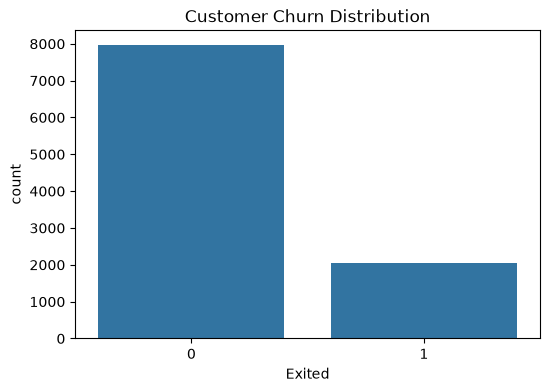

In [14]:
plt.figure(figsize=(6,4))
sns.countplot(x='Exited', data=df)
plt.title("Customer Churn Distribution")
plt.show()

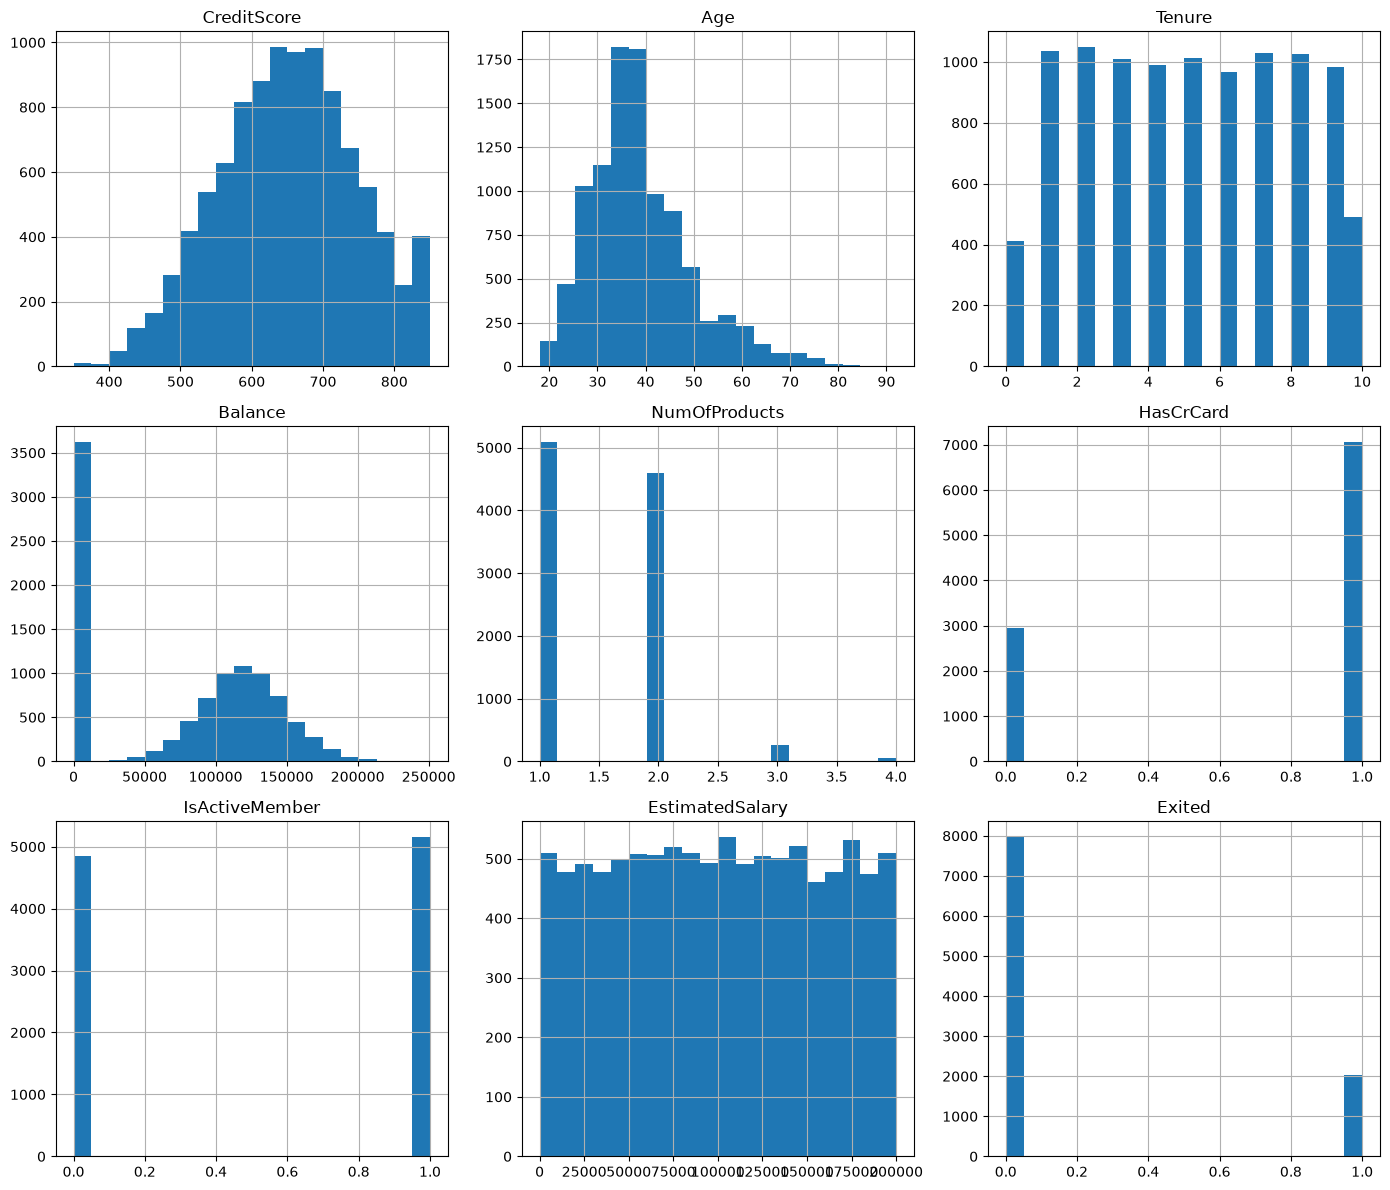

In [17]:
num_cols = df.select_dtypes(include=np.number).columns

df[num_cols].hist(
    figsize=(14,12),
    bins=20
)

plt.tight_layout()
plt.show()

Above graph shows that there are 3500+ zero balance acounts present in the data

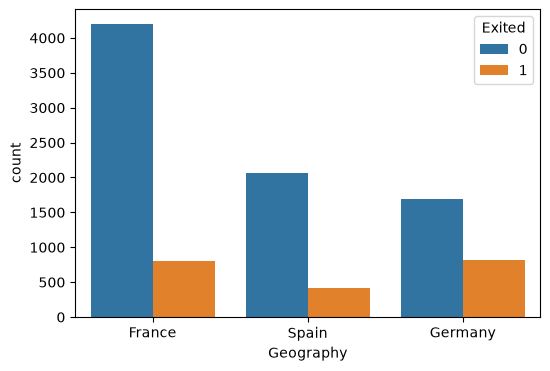

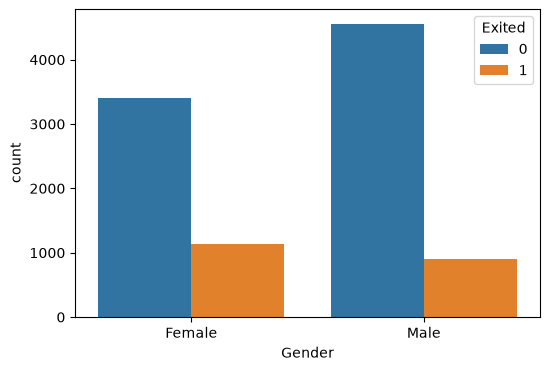

In [18]:
cat_cols = ['Geography','Gender']

for col in cat_cols:

    plt.figure(figsize=(6,4))

    sns.countplot(
        x=col,
        hue='Exited',
        data=df
    )

    plt.show()

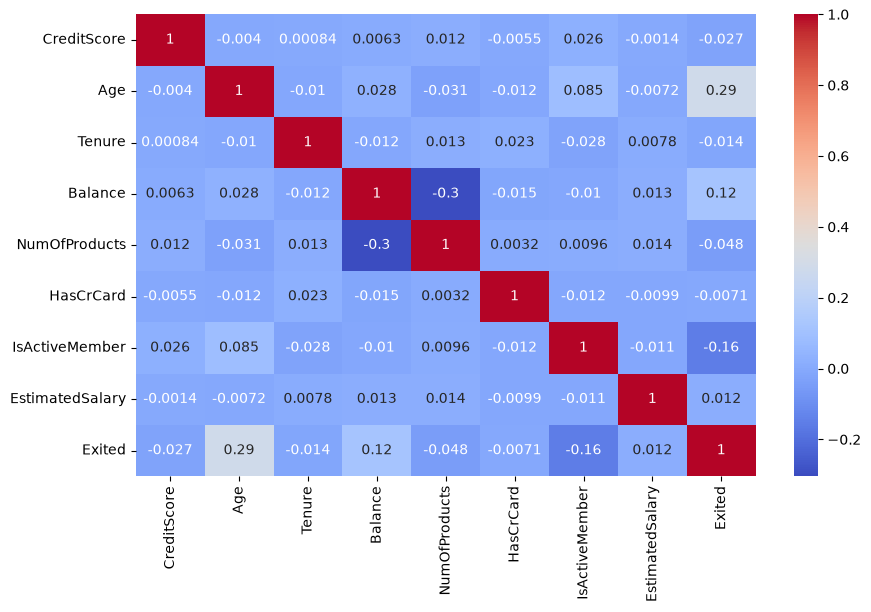

In [20]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.show()

Correlation heatmap does not show any multicolinearity issue in the dataset

In [21]:
numeric_columns = df.select_dtypes(include=np.number).columns

skew_df = pd.DataFrame({
    'Feature': numeric_columns,
    'Skewness': [df[col].skew() for col in numeric_columns]
})

skew_df.sort_values('Skewness', ascending=False)

,Feature,Skewness
8,Exited,1.471611
1,Age,1.011320
4,NumOfProducts,0.745568
2,Tenure,0.010991
7,EstimatedSalary,0.002085
6,IsActiveMember,-0.060437
0,CreditScore,-0.071607
3,Balance,-0.141109
5,HasCrCard,-0.901812


No extreme skewness is detected, as Exited column is a target variable and histogram of age column shows realistic spread of age values with max cutomers having age between 30-45

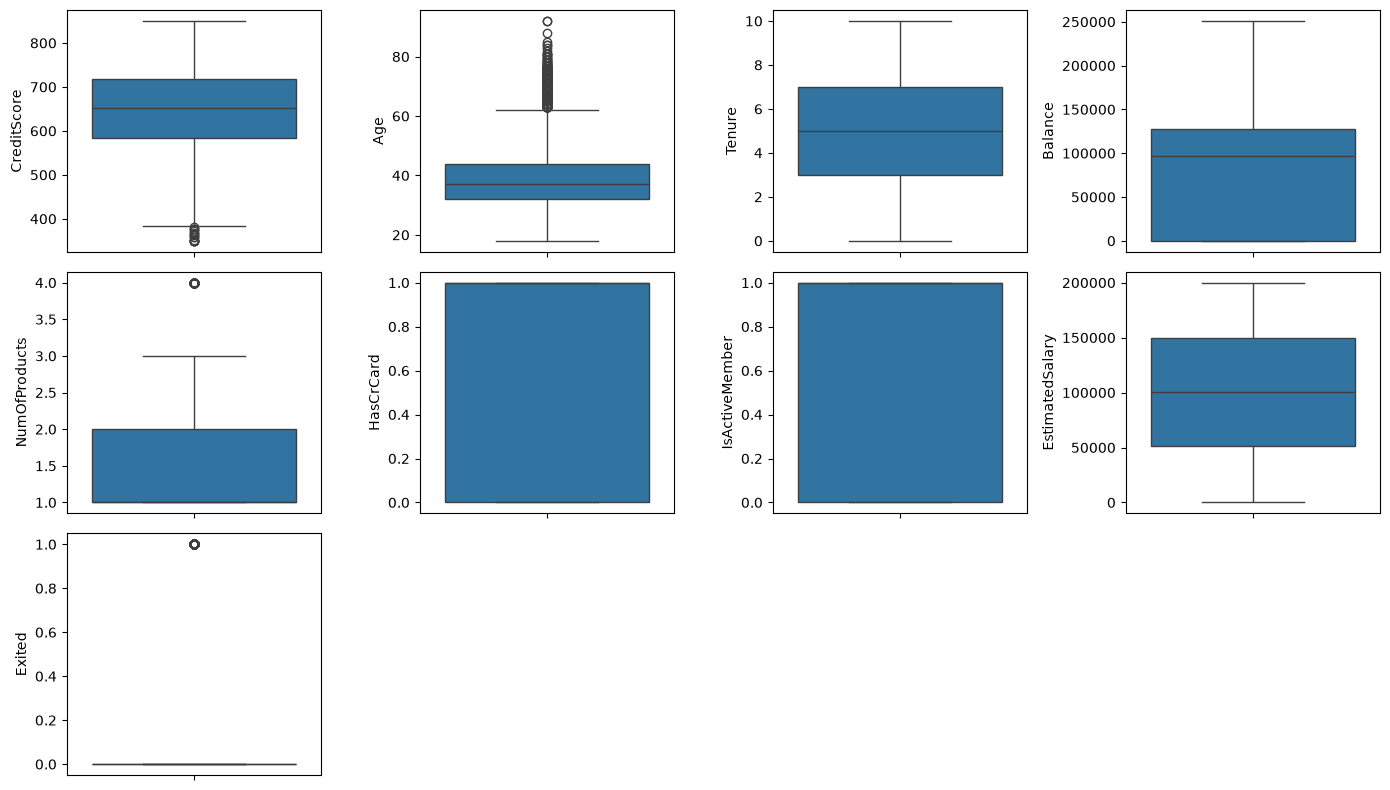

In [24]:
plt.figure(figsize=(14,8))

for i,col in enumerate(numeric_columns,1):

    plt.subplot(3,4,i)

    sns.boxplot(y=df[col])

plt.tight_layout()
plt.show()

Age column seems to have lot of outliers, lets check if it has legitimate values

In [ ]:
df["Age"].describe()

count    10000.000000
mean        38.921800
std         10.487806
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max         92.000000
Name: Age, dtype: float64

Minimum age 18 and maximum 92 are acceptable values so no need of outlier treatment as well.

### Encoding Categorical Variables

In [27]:
df = pd.get_dummies(
    df,
    columns=['Geography','Gender'],
    drop_first=True,
    dtype=int
)

In [29]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


### Feature Split

In [30]:
X = df.drop('Exited',axis=1)

y = df['Exited']

In [31]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Feature Scaling

In [34]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

### Creating Models

#### Basic ANN Model

In [35]:
ann1 = Sequential()

ann1.add(Dense(
    64,
    activation='relu',
    input_dim=X_train.shape[1]
))

ann1.add(Dense(
    32,
    activation='relu'
))

ann1.add(Dense(
    1,
    activation='sigmoid'
))

In [36]:
ann1.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [37]:
history1 = ann1.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8041 - loss: 0.4559 - val_accuracy: 0.8294 - val_loss: 0.4170
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8292 - loss: 0.3982 - val_accuracy: 0.8456 - val_loss: 0.3809
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8458 - loss: 0.3674 - val_accuracy: 0.8606 - val_loss: 0.3506
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8577 - loss: 0.3527 - val_accuracy: 0.8669 - val_loss: 0.3404
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 909us/step - accuracy: 0.8586 - loss: 0.3456 - val_accuracy: 0.8700 - val_loss: 0.3380
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8575 - loss: 0.3426 - val_accuracy: 0.8750 - val_loss: 0.3352
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8589 - loss: 0.3380 - val_accuracy: 0.8706 - val_loss: 0.3378
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8594 - loss: 0.3353 - val_accuracy: 

In [38]:
loss1, acc1 = ann1.evaluate(X_test, y_test)

print("ANN Accuracy:", acc1)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 812us/step - accuracy: 0.8585 - loss: 0.3724
ANN Accuracy: 0.8585000038146973


#### ANN + Dropout + EarlyStopping + ModelCheckpoint

In [39]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [40]:
checkpoint = ModelCheckpoint(
    'best_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

In [41]:
ann2 = Sequential()

ann2.add(Dense(
    128,
    activation='relu',
    input_dim=X_train.shape[1]
))
ann2.add(Dropout(0.3))

ann2.add(Dense(
    64,
    activation='relu'
))
ann2.add(Dropout(0.3))

ann2.add(Dense(
    32,
    activation='relu'
))
ann2.add(Dropout(0.2))

ann2.add(Dense(
    1,
    activation='sigmoid'
))

In [42]:
ann2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [43]:
history2 = ann2.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[
        early_stop,
        checkpoint
    ],
    verbose=1
)

Epoch 1/100
181/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7933 - loss: 0.4811
Epoch 1: val_accuracy improved from None to 0.82250, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7966 - loss: 0.4750 - val_accuracy: 0.8225 - val_loss: 0.4222
Epoch 2/100
187/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8153 - loss: 0.4339
Epoch 2: val_accuracy improved from 0.82250 to 0.85188, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8150 - loss: 0.4332 - val_accuracy: 0.8519 - val_loss: 0.3876
Epoch 3/100
198/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8319 - loss: 0.4056
Epoch 3: val_accuracy improved from 0.85188 to 0.86375, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8319 - loss: 0.4058 - val_accu

In [45]:
loss2, acc2 = ann2.evaluate(X_test, y_test)

print("ANN Accuracy:", acc2)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8630 - loss: 0.3399
ANN Accuracy: 0.8629999756813049


In [46]:
def evaluate_model(model):

    pred_prob = model.predict(X_test)

    pred = (pred_prob > 0.5).astype(int)

    accuracy = accuracy_score(y_test,pred)

    auc = roc_auc_score(
        y_test,
        pred_prob
    )

    print("Accuracy :",accuracy)

    print("ROC AUC :",auc)

    print(
        classification_report(
            y_test,
            pred
        )
    )

    sns.heatmap(
        confusion_matrix(y_test,pred),
        annot=True,
        fmt='d'
    )

    plt.show()

    return accuracy, auc

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Accuracy : 0.8585
ROC AUC : 0.8402562809342471
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      1593
           1       0.71      0.51      0.60       407

    accuracy                           0.86      2000
   macro avg       0.80      0.73      0.76      2000
weighted avg       0.85      0.86      0.85      2000



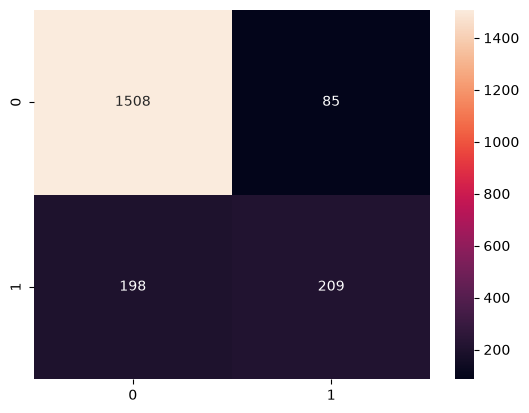

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 914us/step
Accuracy : 0.863
ROC AUC : 0.8584717228785026
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.78      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.83      0.71      0.75      2000
weighted avg       0.85      0.86      0.85      2000



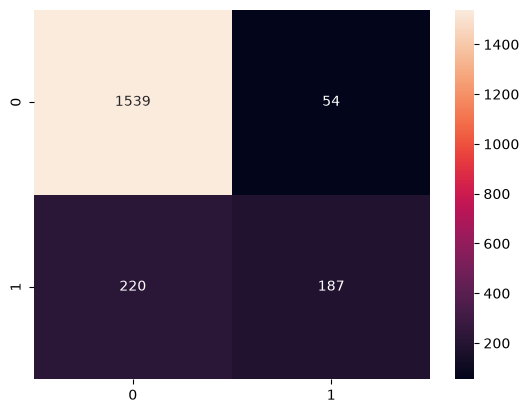

In [47]:
acc1, auc1 = evaluate_model(ann1)

acc2, auc2 = evaluate_model(ann2)

### Using Keras Tuner

In [48]:
def build_model(hp):

    model = Sequential()

    model.add(
        Dense(
            units=hp.Int(
                'input_units',
                min_value=32,
                max_value=256,
                step=32
            ),
            activation=hp.Choice(
                'activation',
                ['relu','tanh']
            ),
            input_dim=X_train.shape[1]
        )
    )

    for i in range(

        hp.Int(
            'hidden_layers',
            1,
            5
        )
    ):

        model.add(
            Dense(
                hp.Int(
                    f'units_{i}',
                    32,
                    256,
                    step=32
                ),
                activation=hp.Choice(
                    'activation',
                    ['relu','tanh']
                )
            )
        )

        model.add(
            Dropout(
                hp.Float(
                    f'dropout_{i}',
                    0.1,
                    0.5,
                    step=0.1
                )
            )
        )

    model.add(
        Dense(
            1,
            activation='sigmoid'
        )
    )

    model.compile(

        optimizer=hp.Choice(
            'optimizer',
            ['adam','rmsprop','nadam']
        ),

        loss='binary_crossentropy',

        metrics=['accuracy']
    )

    return model

In [ ]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,
    overwrite=True,
    directory='tuner_dir',
    project_name='bank_churn'
)

In [50]:
tuner.search(

    X_train,

    y_train,

    validation_split=0.2,

    epochs=20,

    callbacks=[early_stop]
)

Trial 10 Complete [00h 00m 10s]
val_accuracy: 0.8731250166893005

Best val_accuracy So Far: 0.8756250143051147
Total elapsed time: 00h 01m 30s


#### Best Hyperparameters

In [51]:
best_hp = tuner.get_best_hyperparameters(1)[0]

print(best_hp.values)

{'input_units': 224, 'activation': 'relu', 'hidden_layers': 5, 'units_0': 256, 'dropout_0': 0.5, 'optimizer': 'adam', 'units_1': 32, 'dropout_1': 0.1, 'units_2': 32, 'dropout_2': 0.1, 'units_3': 32, 'dropout_3': 0.1, 'units_4': 32, 'dropout_4': 0.1}


#### Training Best Tuned Model

In [52]:
best_model = tuner.get_best_models(1)[0]

In [53]:
history_best = best_model.fit(

    X_train,

    y_train,

    validation_split=0.2,

    epochs=50,

    callbacks=[early_stop],

    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8606 - loss: 0.3428 - val_accuracy: 0.8731 - val_loss: 0.3377
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8630 - loss: 0.3360 - val_accuracy: 0.8650 - val_loss: 0.3338
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8653 - loss: 0.3362 - val_accuracy: 0.8694 - val_loss: 0.3359
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8614 - loss: 0.3388 - val_accuracy: 0.8694 - val_loss: 0.3362
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8611 - loss: 0.3348 - val_accuracy: 0.8706 - val_loss: 0.3383
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8642 - loss: 0.3317 - val_accuracy: 0.8725 - val_loss: 0.3307
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8658 - loss: 0.3278 - val_accuracy: 0.8712 - val_loss: 0.3351
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8675 - loss: 0.3291 - val_accuracy: 0.

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Accuracy : 0.8585
ROC AUC : 0.8560802713345085
              precision    recall  f1-score   support

           0       0.87      0.96      0.92      1593
           1       0.75      0.46      0.57       407

    accuracy                           0.86      2000
   macro avg       0.81      0.71      0.74      2000
weighted avg       0.85      0.86      0.84      2000



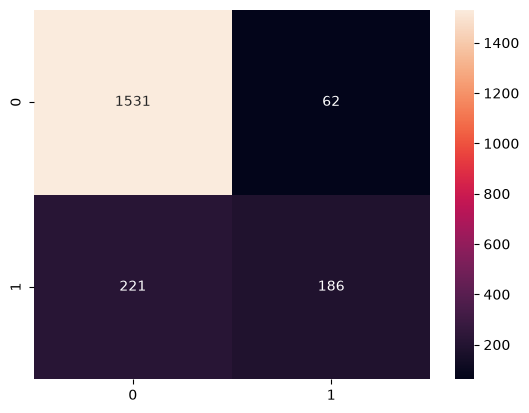

In [54]:
best_acc, best_auc = evaluate_model(
    best_model
)

### Comparing All Models

In [55]:
results = pd.DataFrame({

    'Model':[
        'Basic ANN',
        'ANN + Dropout',
        'Keras Tuner Best Model'
    ],

    'Accuracy':[
        acc1,
        acc2,
        best_acc
    ],

    'ROC_AUC':[
        auc1,
        auc2,
        best_auc
    ]
})

In [56]:
results.sort_values(
    'Accuracy',
    ascending=False
)

,Model,Accuracy,ROC_AUC
1,ANN + Dropout,0.8630,0.858472
0,Basic ANN,0.8585,0.840256
2,Keras Tuner Best Model,0.8585,0.856080


### Accuracy Comparison Plot

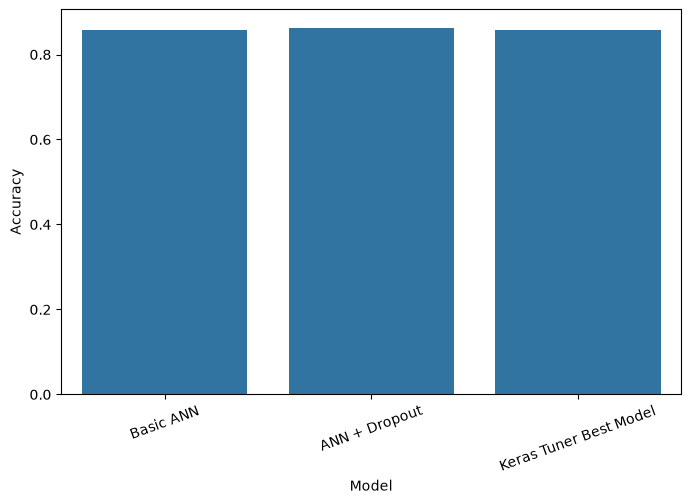

In [57]:
plt.figure(figsize=(8,5))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=results
)

plt.xticks(rotation=20)

plt.show()

### Final Model Selection

In [58]:
best_model.save(
    "Final_Bank_Churn_Model.keras"
)

print("Best model saved successfully.")

Best model saved successfully.


The Bank Customer Churn dataset was successfully analyzed and multiple ANN models were developed to predict customer churn. Among all models, the ANN with Dropout Regularization achieved the best performance with an accuracy of 86.30% and a ROC-AUC score of 0.8585. The use of dropout helped reduce overfitting and improved the model's generalization ability. Therefore, the ANN with Dropout was selected as the final model for predicting customer churn and can be used to identify customers at risk of leaving the bank.